In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data.loader import carregar_cotacoes

In [2]:

arquivo = "../data/raw/COTAHIST_A2024.txt"

df = carregar_cotacoes(arquivo)

df.shape
df.head()
print("Shape após filtro TIPREG:", df.shape)
print(df['TIPREG'].value_counts())

Shape após filtro TIPREG: (2635563, 26)
TIPREG
01    2635561
00          1
99          1
Name: count, dtype: int64


In [3]:
# TIPREG veio como string ('00', '01', '99')
df = df[df['TIPREG'] == '01'].copy()

print("Shape após filtro TIPREG='01':", df.shape)
print(df['TIPREG'].value_counts())

Shape após filtro TIPREG='01': (2635561, 26)
TIPREG
01    2635561
Name: count, dtype: int64


In [4]:
# TIPREG não é mais útil; colunas 100% NaN também podem sair
df = df.drop(columns=['TIPREG'])

# Remove colunas totalmente vazias (comum no COTAHIST para à vista)
df = df.dropna(axis=1, how='all')

print("Colunas restantes:", df.columns.tolist())
print("Shape:", df.shape)

Colunas restantes: []
Shape: (0, 0)


In [4]:
print(repr(df.columns.tolist()))

['TIPREG', 'DATA_PREGÃO', 'CODBDI', 'CODNEG', 'TPMERC', 'NOMRES', 'ESPECI', 'PRAZOT', 'MODREF', 'PREABE', 'PREMAX', 'PREMIN', 'PREMED', 'PREULT', 'PREOFC', 'PREOFV', 'TOTNEG', 'QUATOT', 'VOLTOT', 'PREEXE', 'INDOPC', 'DATVEN', 'FATCOT', 'PTOEXE', 'CODISI', 'DISMES']


In [9]:
import unicodedata

def normalizar(s):
    # Remove acentos, espaços e caracteres estranhos
    s = unicodedata.normalize('NFKD', str(s))
    s = ''.join(c for c in s if not unicodedata.combining(c))
    return s.strip().upper()

df.columns = [normalizar(c) for c in df.columns]
print(df.columns.tolist())

[]


In [4]:
df['DATA'] = pd.to_datetime(df['DATA_PREGÃO'], format='%Y%m%d')
df = df.drop(columns=['DATA_PREGÃO'])

print(df['DATA'].min(), "→", df['DATA'].max())

2024-01-02 00:00:00 → 2024-12-30 00:00:00


In [5]:
# Colunas de preço (vêm multiplicadas por 100 no COTAHIST)
preco_cols = ['PREABE','PREMAX','PREMIN','PREMED','PREULT',
              'PREOFC','PREOFV','PREEXE','PTOEXE']

for c in preco_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce') / 100.0

# Colunas de quantidade/volume (inteiras, sem divisão)
qtd_cols = ['TOTNEG','QUATOT','VOLTOT','FATCOT','DISMES']
for c in qtd_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

# CODBDI, TPMERC, INDOPC também são numéricos
for c in ['CODBDI','TPMERC','INDOPC']:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

print(df.dtypes)

TIPREG               str
CODBDI             int64
CODNEG               str
TPMERC             int64
NOMRES               str
ESPECI               str
PRAZOT               str
MODREF               str
PREABE           float64
PREMAX           float64
PREMIN           float64
PREMED           float64
PREULT           float64
PREOFC           float64
PREOFV           float64
TOTNEG             int64
QUATOT             int64
VOLTOT             int64
PREEXE           float64
INDOPC             int64
DATVEN               str
FATCOT             int64
PTOEXE           float64
CODISI               str
DISMES             int64
DATA      datetime64[us]
dtype: object


In [6]:
df = df[df['TPMERC'] == 10].copy()
print("Shape após TPMERC=10:", df.shape)

Shape após TPMERC=10: (322397, 26)


In [7]:
df = df.sort_values(['CODNEG','DATA']).reset_index(drop=True)

antes = len(df)
df = df[df['PREULT'] > 0].copy()
print(f"Removidas {antes - len(df)} linhas com PREULT=0")

Removidas 0 linhas com PREULT=0


In [8]:
liq = df.groupby('CODNEG')['VOLTOT'].sum().sort_values(ascending=False)
print(liq.head(20))

# Top 50 mais líquidos (mais simples de interpretar que percentil)
top50 = liq.head(50).index
df = df[df['CODNEG'].isin(top50)].copy()

print("Shape final:", df.shape)
print("Tickers:", df['CODNEG'].nunique())

CODNEG
VALE3     36350033869000
PETR4     35539779262900
ITUB4     20045798593200
BOVA11    17480623123104
BBDC4     13448786662600
IBOV11    13329626609700
B3SA3     12883232900800
BBAS3     11893672642800
PETR3     10971023823600
RENT3     10729172887900
PRIO3     10173886786900
SUZB3      9673532666400
ABEV3      9169615572300
SBSP3      8951191702900
ELET3      7648548666500
BPAC11     7497726304200
WEGE3      7364894171800
EMBR3      6779328460300
LREN3      6639231554900
HAPV3      6501325786400
Name: VOLTOT, dtype: int64
Shape final: (12234, 26)
Tickers: 50


In [9]:
df.to_parquet('cotahist_2024_limpo.parquet', index=False)

In [10]:
print("Shape:", df.shape)
print("\nColunas:", df.columns.tolist())
print("\nDtypes:")
print(df.dtypes)
print("\nRange de datas:", df['DATA'].min(), "→", df['DATA'].max())
print("Tickers únicos:", df['CODNEG'].nunique())
print("\nPrimeiras linhas:")
df.head()

Shape: (12234, 26)

Colunas: ['TIPREG', 'CODBDI', 'CODNEG', 'TPMERC', 'NOMRES', 'ESPECI', 'PRAZOT', 'MODREF', 'PREABE', 'PREMAX', 'PREMIN', 'PREMED', 'PREULT', 'PREOFC', 'PREOFV', 'TOTNEG', 'QUATOT', 'VOLTOT', 'PREEXE', 'INDOPC', 'DATVEN', 'FATCOT', 'PTOEXE', 'CODISI', 'DISMES', 'DATA']

Dtypes:
TIPREG               str
CODBDI             int64
CODNEG               str
TPMERC             int64
NOMRES               str
ESPECI               str
PRAZOT               str
MODREF               str
PREABE           float64
PREMAX           float64
PREMIN           float64
PREMED           float64
PREULT           float64
PREOFC           float64
PREOFV           float64
TOTNEG             int64
QUATOT             int64
VOLTOT             int64
PREEXE           float64
INDOPC             int64
DATVEN               str
FATCOT             int64
PTOEXE           float64
CODISI               str
DISMES             int64
DATA      datetime64[us]
dtype: object

Range de datas: 2024-01-02 00:00:00 → 

,TIPREG,CODBDI,CODNEG,TPMERC,NOMRES,ESPECI,PRAZOT,MODREF,PREABE,PREMAX,...,QUATOT,VOLTOT,PREEXE,INDOPC,DATVEN,FATCOT,PTOEXE,CODISI,DISMES,DATA
8503,01,2,ABEV3,10,AMBEV S/A,ON EJ,NaN,R$,13.72,13.73,...,11690200,15983911100,0.0,0,99991231,1,0.0,BRABEVACNOR1,127,2024-01-02
8504,01,2,ABEV3,10,AMBEV S/A,ON EJ,NaN,R$,13.67,13.75,...,17612200,24001810300,0.0,0,99991231,1,0.0,BRABEVACNOR1,127,2024-01-03
8505,01,2,ABEV3,10,AMBEV S/A,ON,NaN,R$,13.60,13.68,...,19996000,27273005700,0.0,0,99991231,1,0.0,BRABEVACNOR1,127,2024-01-04
8506,01,2,ABEV3,10,AMBEV S/A,ON,NaN,R$,13.62,13.69,...,18293900,24899756600,0.0,0,99991231,1,0.0,BRABEVACNOR1,127,2024-01-05
8507,01,2,ABEV3,10,AMBEV S/A,ON,NaN,R$,13.61,13.75,...,11014600,15093238100,0.0,0,99991231,1,0.0,BRABEVACNOR1,127,2024-01-08


In [11]:
import matplotlib.pyplot as plt

# Top 10 por volume
top_vol = df.groupby('CODNEG')['VOLTOT'].sum().sort_values(ascending=False).head(10)
print(top_vol)

# Quantos dias cada ticker tem
dias = df.groupby('CODNEG')['DATA'].count().sort_values(ascending=False)
print("\nDias por ticker:")
print(dias.describe())
print("\nTickers com menos de 200 dias:", (dias < 200).sum())

CODNEG
VALE3     36350033869000
PETR4     35539779262900
ITUB4     20045798593200
BOVA11    17480623123104
BBDC4     13448786662600
IBOV11    13329626609700
B3SA3     12883232900800
BBAS3     11893672642800
PETR3     10971023823600
RENT3     10729172887900
Name: VOLTOT, dtype: int64

Dias por ticker:
count     50.000000
mean     244.680000
std       35.298401
min       12.000000
25%      251.000000
50%      251.000000
75%      251.000000
max      251.000000
Name: DATA, dtype: float64

Tickers com menos de 200 dias: 2


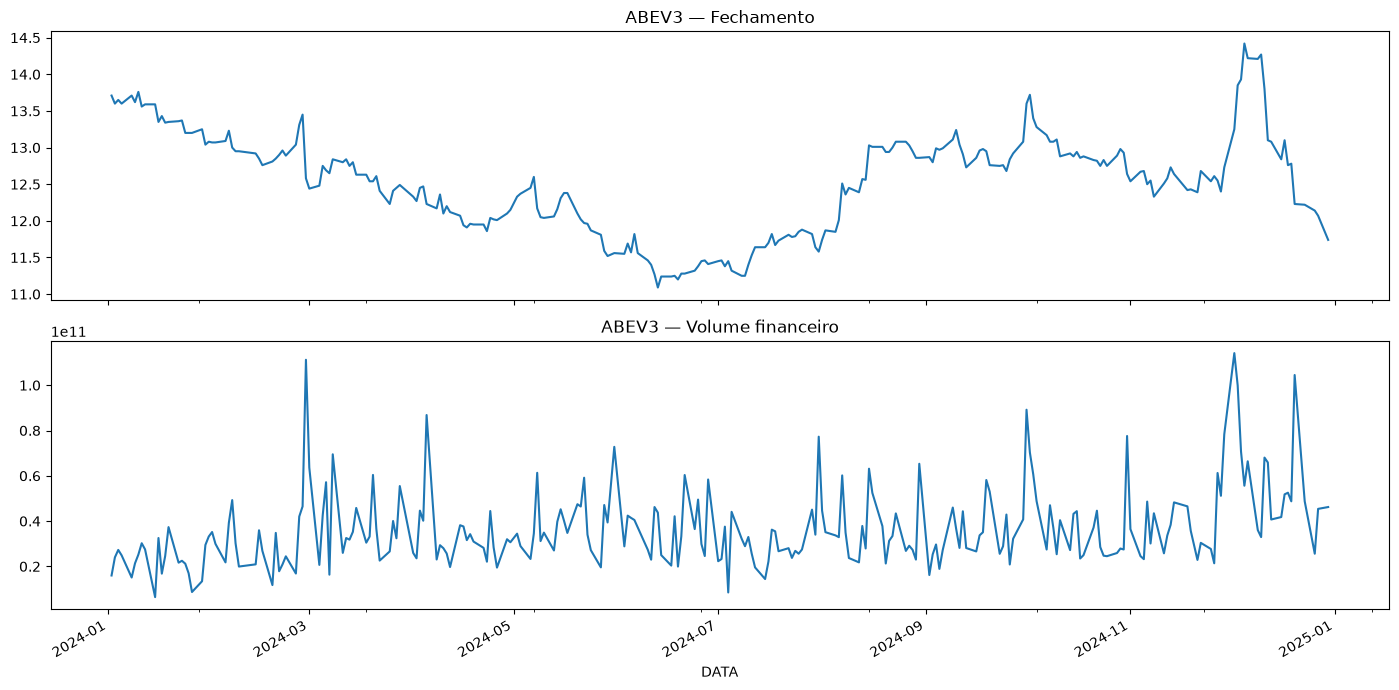

In [12]:
ticker = 'ABEV3'   # troque se ele não estiver no seu top50
sub = df[df['CODNEG'] == ticker].set_index('DATA').sort_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
sub['PREULT'].plot(ax=axes[0], title=f'{ticker} — Fechamento')
sub['VOLTOT'].plot(ax=axes[1], title=f'{ticker} — Volume financeiro')
plt.tight_layout()
plt.show()

In [13]:
import numpy as np

df = df.sort_values(['CODNEG', 'DATA']).reset_index(drop=True)

# Retorno log diário
df['ret'] = df.groupby('CODNEG')['PREULT'].transform(
    lambda x: np.log(x).diff()
)

print("Estatísticas dos retornos:")
print(df['ret'].describe())

# Quantos NaN? (primeiro dia de cada ticker)
print("\nNaNs em ret:", df['ret'].isna().sum())

Estatísticas dos retornos:
count    12184.000000
mean        -0.000804
std          0.029858
min         -0.704547
25%         -0.010737
50%         -0.000784
75%          0.009495
max          2.298790
Name: ret, dtype: float64

NaNs em ret: 50


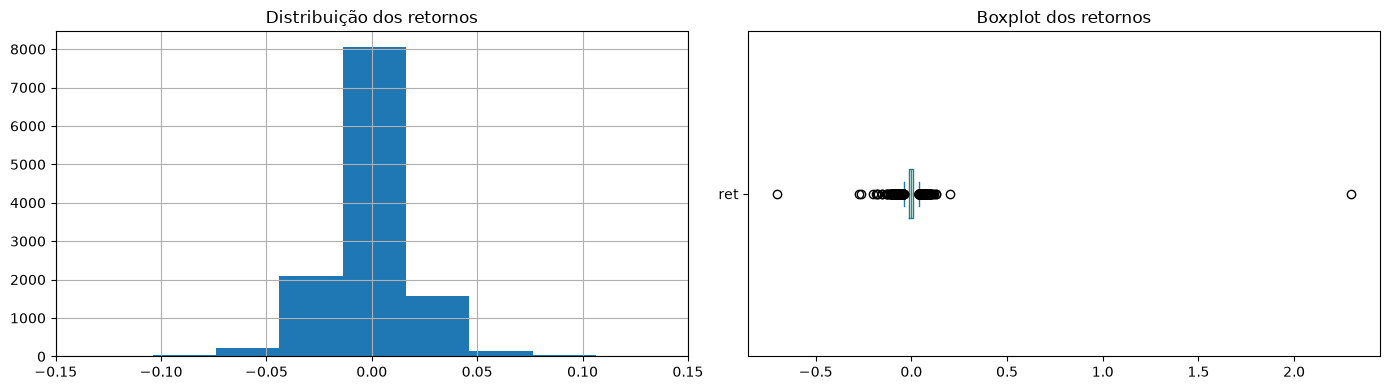

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df['ret'].dropna().hist(bins=100, ax=axes[0])
axes[0].set_title('Distribuição dos retornos')
axes[0].set_xlim(-0.15, 0.15)

df['ret'].dropna().plot(kind='box', ax=axes[1], vert=False)
axes[1].set_title('Boxplot dos retornos')

plt.tight_layout()
plt.show()

In [15]:
# Ver quais linhas têm retornos extremos
extremos = df[df['ret'].abs() > 0.30][['CODNEG','DATA','PREABE','PREULT','ret','QUATOT','VOLTOT']]
print(extremos.sort_values('ret').head(30))

     CODNEG       DATA  PREABE  PREULT       ret    QUATOT       VOLTOT
1076  BBAS3 2024-04-16   28.23   27.91 -0.704547  22923700  64045699000
6889  MGLU3 2024-05-27   12.83   13.15  2.298790  27976500  35662659200


In [16]:
# Filtra BBAS3 e mostra os dias em torno de 2024-04-16
bbas = df[df['CODNEG'] == 'BBAS3'].sort_values('DATA').reset_index(drop=True)
bbas.loc[bbas['DATA'].between('2024-04-12','2024-04-18'),
         ['DATA','PREABE','PREULT','ret']]

,DATA,PREABE,PREULT,ret
70,2024-04-12,57.74,56.99,-0.013074
71,2024-04-15,57.26,56.46,-0.009343
72,2024-04-16,28.23,27.91,-0.704547
73,2024-04-17,28.00,27.97,0.002147
74,2024-04-18,28.15,27.93,-0.001431


In [17]:
# Duplicatas de (ticker, data)?
dup = df.duplicated(subset=['CODNEG','DATA'], keep=False)
print("Linhas duplicadas por (ticker, data):", dup.sum())

if dup.any():
    print(df[dup].sort_values(['CODNEG','DATA']).head(20))

Linhas duplicadas por (ticker, data): 0


In [18]:
# BBAS3 em abril — PREULT dia a dia
bbas = df[df['CODNEG']=='BBAS3'].sort_values('DATA')
bbas[bbas['DATA'].between('2024-04-10','2024-04-20')][['DATA','PREABE','PREMAX','PREMIN','PREULT']]

,DATA,PREABE,PREMAX,PREMIN,PREULT
1072,2024-04-10,58.34,58.50,57.33,57.60
1073,2024-04-11,57.50,58.07,57.34,57.74
1074,2024-04-12,57.74,57.85,56.82,56.99
1075,2024-04-15,57.26,57.34,56.21,56.46
1076,2024-04-16,28.23,28.40,27.54,27.91
1077,2024-04-17,28.00,28.17,27.78,27.97
1078,2024-04-18,28.15,28.23,27.70,27.93
1079,2024-04-19,28.02,28.02,27.66,27.71


In [19]:
# MGLU3 em maio
mglu = df[df['CODNEG']=='MGLU3'].sort_values('DATA')
mglu[mglu['DATA'].between('2024-05-20','2024-05-30')][['DATA','PREABE','PREMAX','PREMIN','PREULT']]

,DATA,PREABE,PREMAX,PREMIN,PREULT
6884,2024-05-20,1.57,1.62,1.56,1.57
6885,2024-05-21,1.56,1.59,1.50,1.55
6886,2024-05-22,1.53,1.53,1.47,1.47
6887,2024-05-23,1.47,1.49,1.40,1.42
6888,2024-05-24,1.40,1.41,1.32,1.32
6889,2024-05-27,12.83,13.19,12.33,13.15
6890,2024-05-28,13.30,13.58,12.28,12.29
6891,2024-05-29,12.25,12.63,12.08,12.08


In [20]:
import numpy as np
import pandas as pd

# 1) Ordena
df = df.sort_values(['CODNEG','DATA']).reset_index(drop=True)

# 2) Calcula retorno bruto
df['ret'] = df.groupby('CODNEG')['PREULT'].transform(
    lambda x: np.log(x).diff()
)

# 3) Identifica dias de split (|ret| > 30%)
mask_split = df['ret'].abs() > 0.30
print("Dias de split detectados:")
print(df[mask_split][['CODNEG','DATA','PREULT','ret']])

# 4) Remove o dia do split E o dia anterior (que está em escala antiga)
idx_remover = set()
for idx in df[mask_split].index:
    ticker = df.loc[idx, 'CODNEG']
    sub_idx = df[df['CODNEG'] == ticker].index.tolist()
    pos = sub_idx.index(idx)
    if pos > 0:
        idx_remover.add(sub_idx[pos-1])
    idx_remover.add(idx)

df = df[~df.index.isin(idx_remover)].reset_index(drop=True)
print(f"\nRemovidas {len(idx_remover)} linhas.")
print(f"Shape: {df.shape}")

# 5) Recalcula retorno (agora sem split)
df['ret'] = df.groupby('CODNEG')['PREULT'].transform(
    lambda x: np.log(x).diff()
)

# 6) Confere
print("\nNova estatística de retorno:")
print(df['ret'].describe())

Dias de split detectados:
     CODNEG       DATA  PREULT       ret
1076  BBAS3 2024-04-16   27.91 -0.704547
6889  MGLU3 2024-05-27   13.15  2.298790

Removidas 4 linhas.
Shape: (12230, 27)

Nova estatística de retorno:
count    12180.000000
mean        -0.000804
std          0.028989
min         -0.711743
25%         -0.010730
50%         -0.000782
75%          0.009500
max          2.158129
Name: ret, dtype: float64


In [21]:
for c in ['VOLTOT','QUATOT','TOTNEG']:
    df[c] = df[c] / 100.0

In [22]:
bbas = df[(df['CODNEG']=='BBAS3') & (df['DATA']=='2024-01-02')]
print(bbas[['QUATOT','PREULT','VOLTOT']])
# Esperado: VOLTOT ≈ QUATOT × PREULT ≈ R$ 300-600 milhões

       QUATOT  PREULT       VOLTOT
1004  81705.0   54.76  447608817.0


In [23]:
df.to_parquet('cotahist_2024_limpo.parquet', index=False)
print("Salvo. Shape final:", df.shape)

Salvo. Shape final: (12230, 27)


In [24]:
# Varre TODOS os outliers, não só |ret| > 0.30
df_diag = df.sort_values(['CODNEG','DATA']).reset_index(drop=True)
df_diag['ret'] = df_diag.groupby('CODNEG')['PREULT'].transform(
    lambda x: np.log(x).diff()
)

# Todos os |ret| > 15%
outliers = df_diag[df_diag['ret'].abs() > 0.15][['CODNEG','DATA','PREULT','ret']]
print(f"Total de outliers |ret| > 15%: {len(outliers)}\n")
print(outliers.sort_values('ret').to_string())

Total de outliers |ret| > 15%: 11

     CODNEG       DATA  PREULT       ret
1075  BBAS3 2024-04-17   27.97 -0.711743
669   AZUL4 2024-08-29    5.50 -0.276253
2841  CMIG4 2024-04-30    9.77 -0.261498
671   AZUL4 2024-09-02    4.41 -0.200671
9451  RENT3 2024-08-14   40.00 -0.184403
5092  GGBR4 2024-04-18   18.77 -0.181700
1279  BBDC4 2024-02-07   13.96 -0.173207
7266  MRVE3 2024-11-28    5.30 -0.151992
6776  LREN3 2024-12-12   13.68 -0.151013
680   AZUL4 2024-09-13    4.95  0.203143
6886  MGLU3 2024-05-28   12.29  2.158129


In [6]:
import numpy as np
import pandas as pd

df = pd.read_parquet('cotahist_2024_limpo.parquet')
df = df.sort_values(['CODNEG','DATA']).reset_index(drop=True)

# 1) Detecta splits pela razão de preços
df['preult_prev'] = df.groupby('CODNEG')['PREULT'].shift(1)
df['razao'] = df['PREULT'] / df['preult_prev']
df['is_split'] = (df['razao'] > 1.5) | (df['razao'] < 0.67)

# 2) Fator ACUMULADO retroativo, mas aplicado do jeito certo:
#    Os dias ANTERIORES ao split ficam multiplicados pelo inverso da razão.
#    Equivale a "elevar" os preços antigos para a escala nova.
df['log_razao_split'] = np.where(df['is_split'], np.log(df['razao']), 0)

# Fator pra dias POSTERIORES = 1 (não mudam)
# Fator pra dias ANTERIORES = produto dos inversos das razões futuras
# Implementação: soma acumulada dos logs "para trás", com sinal invertido
df['soma_logs_futuros'] = (
    df.iloc[::-1]
      .groupby('CODNEG')['log_razao_split']
      .cumsum()
      .iloc[::-1]
)
df['soma_logs_futuros'] = df.groupby('CODNEG')['soma_logs_futuros'].shift(-1).fillna(0)

# Fator que AUMENTA os preços antigos para a escala atual
df['fator_split'] = np.exp(df['soma_logs_futuros'])

# 3) Aplica nos preços
for c in ['PREABE','PREMAX','PREMIN','PREMED','PREULT','PREOFC','PREOFV']:
    if c in df.columns:
        df[c + '_adj'] = df[c] * df['fator_split']

# 4) Retorno
df['ret'] = df.groupby('CODNEG')['PREULT_adj'].transform(
    lambda x: np.log(x).diff()
)

print(df['ret'].describe())

count    12180.000000
mean        -0.000923
std          0.020399
min         -0.276253
25%         -0.010728
50%         -0.000779
75%          0.009495
max          0.203143
Name: ret, dtype: float64


In [7]:
# BBAS3
bbas = df[(df['CODNEG']=='BBAS3') & (df['DATA'].between('2024-04-12','2024-04-18'))]
print("BBAS3:")
print(bbas[['DATA','PREULT','PREULT_adj','fator_split','ret']].to_string())

# MGLU3
mglu = df[(df['CODNEG']=='MGLU3') & (df['DATA'].between('2024-05-24','2024-05-29'))]
print("\nMGLU3:")
print(mglu[['DATA','PREULT','PREULT_adj','fator_split','ret']].to_string())

BBAS3:
           DATA  PREULT  PREULT_adj  fator_split       ret
1074 2024-04-12   56.99       27.97     0.490788 -0.013074
1075 2024-04-17   27.97       27.97     1.000000  0.000000
1076 2024-04-18   27.93       27.93     1.000000 -0.001431

MGLU3:
           DATA  PREULT  PREULT_adj  fator_split       ret
6886 2024-05-28   12.29       12.29          1.0  0.000000
6887 2024-05-29   12.08       12.08          1.0 -0.017235


In [8]:
print("\nOutliers remanescentes |ret| > 0.15:")
print(df[df['ret'].abs() > 0.15][['CODNEG','DATA','PREULT','ret']].to_string())


Outliers remanescentes |ret| > 0.15:
     CODNEG       DATA  PREULT       ret
669   AZUL4 2024-08-29    5.50 -0.276253
671   AZUL4 2024-09-02    4.41 -0.200671
680   AZUL4 2024-09-13    4.95  0.203143
1279  BBDC4 2024-02-07   13.96 -0.173207
2841  CMIG4 2024-04-30    9.77 -0.261498
5092  GGBR4 2024-04-18   18.77 -0.181700
6776  LREN3 2024-12-12   13.68 -0.151013
7266  MRVE3 2024-11-28    5.30 -0.151992
9451  RENT3 2024-08-14   40.00 -0.184403


In [11]:
test = df[(df['CODNEG']=='BBAS3') & (df['DATA']=='2024-01-02')]
print(test[['QUATOT','PREULT','VOLTOT']])

      QUATOT  PREULT      VOLTOT
1004  817.05   54.76  4476088.17


In [10]:
for c in ['VOLTOT','QUATOT','TOTNEG']:
    df[c] = df[c] / 100.0

In [5]:
import numpy as np
import pandas as pd

# Garante ordenação
df = df.sort_values(['CODNEG','DATA']).reset_index(drop=True)

# Garante que existe PREULT_adj; senão, cria
if 'PREULT_adj' not in df.columns:
    df['PREULT_adj'] = df['PREULT']

# Retorno base
df['ret'] = df.groupby('CODNEG')['PREULT_adj'].transform(
    lambda x: np.log(x).diff()
)
print("Shape base:", df.shape)

NameError: name 'df' is not defined

In [13]:
g = df.groupby('CODNEG')

for lag in [1, 2, 3, 5, 10, 21]:
    df[f'ret_lag{lag}'] = g['ret'].shift(lag)

# Retorno acumulado em janelas (momentum)
df['ret_cum5']  = g['ret'].transform(lambda x: x.rolling(5).sum())
df['ret_cum21'] = g['ret'].transform(lambda x: x.rolling(21).sum())
df['ret_cum63'] = g['ret'].transform(lambda x: x.rolling(63).sum())

print("Após Bloco 1:", df.shape)

Após Bloco 1: (12230, 49)


In [14]:
g = df.groupby('CODNEG')

# Vol realizado em várias janelas
df['vol5']  = g['ret'].transform(lambda x: x.rolling(5).std())
df['vol21'] = g['ret'].transform(lambda x: x.rolling(21).std())
df['vol63'] = g['ret'].transform(lambda x: x.rolling(63).std())

# Razão vol curta / vol longa (regime de volatilidade)
df['vol_ratio'] = df['vol5'] / (df['vol21'] + 1e-9)

# Range intradiário (proxy de volatilidade intraday)
df['range'] = (df['PREMAX'] - df['PREMIN']) / df['PREULT'].replace(0, np.nan)

# Range médio
df['range_ma21'] = g['range'].transform(lambda x: x.rolling(21).mean())

print("Após Bloco 2:", df.shape)

Após Bloco 2: (12230, 55)


In [15]:
g = df.groupby('CODNEG')

for w in [5, 21, 63]:
    df[f'mm{w}'] = g['PREULT_adj'].transform(lambda x: x.rolling(w).mean())
    # Distância relativa da MM (feature normalizada, ótima p/ modelo)
    df[f'dist_mm{w}'] = (df['PREULT_adj'] / df[f'mm{w}']) - 1

# Cruzamento de MMs (sinal clássico)
df['mm_cross'] = (df['mm5'] / df['mm21']) - 1

# Posição na banda de Bollinger (20 dias, 2 desvios)
df['bb_mid'] = g['PREULT_adj'].transform(lambda x: x.rolling(20).mean())
df['bb_std'] = g['PREULT_adj'].transform(lambda x: x.rolling(20).std())
df['bb_pos'] = (df['PREULT_adj'] - df['bb_mid']) / (2 * df['bb_std'] + 1e-9)

print("Após Bloco 3:", df.shape)

Após Bloco 3: (12230, 65)


In [16]:
def rsi(series, window=14):
    delta = series.diff()
    ganho = delta.clip(lower=0).rolling(window).mean()
    perda = (-delta.clip(upper=0)).rolling(window).mean()
    rs = ganho / (perda + 1e-9)
    return 100 - (100 / (1 + rs))

g = df.groupby('CODNEG')

# RSI 14
df['rsi14'] = g['PREULT_adj'].transform(lambda x: rsi(x, 14))

# MACD: EMA12 - EMA26, e a "signal" EMA9 do MACD
def macd(series):
    ema12 = series.ewm(span=12, adjust=False).mean()
    ema26 = series.ewm(span=26, adjust=False).mean()
    macd_line = ema12 - ema26
    signal = macd_line.ewm(span=9, adjust=False).mean()
    return macd_line, signal

macd_df = g['PREULT_adj'].transform(lambda x: macd(x)[0])
df['macd'] = macd_df
df['macd_signal'] = g['PREULT_adj'].transform(lambda x: macd(x)[1])
df['macd_hist'] = df['macd'] - df['macd_signal']

# Normaliza MACD pelo preço (senão explode em escala)
df['macd_norm'] = df['macd'] / df['PREULT_adj']

print("Após Bloco 4:", df.shape)

Após Bloco 4: (12230, 70)


In [17]:
g = df.groupby('CODNEG')

# Volume relativo (hoje vs média 21d)
df['vol_ma21'] = g['VOLTOT'].transform(lambda x: x.rolling(21).mean())
df['vol_rel'] = df['VOLTOT'] / (df['vol_ma21'] + 1e-9)

# Log do volume (estabiliza escala)
df['log_vol'] = np.log1p(df['VOLTOT'])

# Número de negócios relativo
df['neg_ma21'] = g['TOTNEG'].transform(lambda x: x.rolling(21).mean())
df['neg_rel'] = df['TOTNEG'] / (df['neg_ma21'] + 1e-9)

# Preço médio vs fechamento (onde o preço fechou dentro do range do dia)
df['close_position'] = (df['PREULT'] - df['PREMIN']) / (df['PREMAX'] - df['PREMIN'] + 1e-9)

print("Após Bloco 5:", df.shape)

Após Bloco 5: (12230, 76)


In [18]:
# Para cada dia, rankeia os tickers por retorno, volume relativo, etc.
df['ret_rank'] = df.groupby('DATA')['ret'].rank(pct=True)
df['vol_rel_rank'] = df.groupby('DATA')['vol_rel'].rank(pct=True)
df['rsi_rank'] = df.groupby('DATA')['rsi14'].rank(pct=True)

# Retorno do mercado no dia (média dos tickers)
df['ret_mercado'] = df.groupby('DATA')['ret'].transform('mean')

# Retorno relativo ao mercado (alpha individual)
df['ret_rel'] = df['ret'] - df['ret_mercado']

# Beta rolling vs mercado (sensibilidade do ativo)
def rolling_beta(g):
    cov = g['ret'].rolling(63).cov(g['ret_mercado'])
    var = g['ret_mercado'].rolling(63).var()
    return cov / (var + 1e-9)

df['beta63'] = df.groupby('CODNEG', group_keys=False).apply(
    lambda x: x['ret'].rolling(63).cov(x['ret_mercado']) / (x['ret_mercado'].rolling(63).var() + 1e-9)
)

print("Após Bloco 6:", df.shape)

Após Bloco 6: (12230, 82)


In [4]:
# Retorno do PRÓXIMO dia
df['target'] = df.groupby('CODNEG')['ret'].shift(-1)

# Versão de classificação (sobe/desce)
df['target_bin'] = (df['target'] > 0).astype(int)

# Target relativo ao mercado (mais robusto)
df['target_rel'] = df['target'] - df.groupby('DATA')['target'].transform('mean')

print("Target criado.")
print(df[['DATA','CODNEG','ret','target','target_bin']].dropna().head(10))

NameError: name 'df' is not defined

In [3]:
# Conta NaN por coluna (features precisam de histórico → primeiros dias ficam NaN)
nans = df.isna().sum().sort_values(ascending=False)
print("Top colunas com NaN:")
print(nans[nans > 0].head(20))

# Remove linhas onde o TARGET é NaN (últimos dias de cada ticker)
df_model = df.dropna(subset=['target']).copy()

# Remove linhas onde features essenciais são NaN (primeiros 63 dias por causa do rolling)
features_essenciais = ['ret_lag1','vol21','rsi14','ret_rank','dist_mm21']
df_model = df_model.dropna(subset=features_essenciais).copy()

print(f"\nShape final para modelagem: {df_model.shape}")
print(f"Tickers: {df_model['CODNEG'].nunique()}")
print(f"Dias: {df_model['DATA'].nunique()}")
print(f"Range: {df_model['DATA'].min()} → {df_model['DATA'].max()}")

NameError: name 'df' is not defined

In [2]:
# Lista as features que vamos usar
FEATURES = [
    # Lags
    'ret_lag1','ret_lag2','ret_lag3','ret_lag5','ret_lag10','ret_lag21',
    'ret_cum5','ret_cum21','ret_cum63',
    # Vol
    'vol5','vol21','vol63','vol_ratio','range','range_ma21',
    # MMs
    'dist_mm5','dist_mm21','dist_mm63','mm_cross','bb_pos',
    # Técnicos
    'rsi14','macd_norm','macd_hist',
    # Volume
    'vol_rel','log_vol','neg_rel','close_position',
    # Cross-sectional
    'ret_rank','vol_rel_rank','rsi_rank','ret_rel','ret_mercado','beta63',
]

# Guarda só o necessário
cols_keep = ['DATA','CODNEG','ret','target','target_bin','target_rel'] + FEATURES
df_model = df_model[cols_keep].copy()

# Checa inf / -inf
df_model[FEATURES] = df_model[FEATURES].replace([np.inf, -np.inf], np.nan)
df_model = df_model.dropna(subset=FEATURES).copy()

print("Shape final:", df_model.shape)
print("Features:", len(FEATURES))
df_model.head()

# Salva
df_model.to_parquet('dataset_modelagem.parquet', index=False)
print("\nSalvo em dataset_modelagem.parquet")

NameError: name 'df_model' is not defined

In [22]:
import pandas as pd
import numpy as np

df_model = pd.read_parquet('dataset_modelagem.parquet')

print("Shape:", df_model.shape)
print("\nRange de datas:", df_model['DATA'].min(), "→", df_model['DATA'].max())
print("Tickers:", df_model['CODNEG'].nunique())
print("Dias únicos:", df_model['DATA'].nunique())

# Distribuição do target
print("\nTarget (retorno do próximo dia):")
print(df_model['target'].describe())

print("\nBalanceamento do target binário:")
print(df_model['target_bin'].value_counts(normalize=True))

Shape: (9082, 39)

Range de datas: 2024-04-03 00:00:00 → 2024-12-27 00:00:00
Tickers: 49
Dias únicos: 187

Target (retorno do próximo dia):
count    9082.000000
mean       -0.001076
std         0.020986
min        -0.276253
25%        -0.010997
50%        -0.000818
75%         0.009507
max         0.203143
Name: target, dtype: float64

Balanceamento do target binário:
target_bin
0    0.533142
1    0.466858
Name: proportion, dtype: float64


In [23]:
# A feature NÃO pode ter correlação absurda com o target
corr = df_model.select_dtypes(include=[np.number]).corr()['target'].drop('target').sort_values()

print("Correlação com target (mais negativas):")
print(corr.head(5))
print("\nCorrelação com target (mais positivas):")
print(corr.tail(10))

Correlação com target (mais negativas):
ret_lag21    -0.054947
vol5         -0.052513
range        -0.047034
beta63       -0.046882
range_ma21   -0.043612
Name: target, dtype: float64

Correlação com target (mais positivas):
neg_rel         0.000851
dist_mm63       0.002624
vol_rel         0.002984
vol_rel_rank    0.004049
log_vol         0.006966
ret_cum63       0.008232
ret_lag5        0.014132
ret_lag3        0.014945
target_bin      0.683915
target_rel      0.853159
Name: target, dtype: float64


In [24]:
print("NaNs por coluna:", df_model.isna().sum().sum())
print("Infs por coluna:", np.isinf(df_model.select_dtypes(include=[np.number])).sum().sum())

NaNs por coluna: 0
Infs por coluna: 0


In [25]:
feats = [c for c in df_model.columns if c not in ['DATA','CODNEG','target','target_bin','target_rel']]
stats = df_model[feats].describe().T
stats['range'] = stats['max'] - stats['min']
print(stats[['mean','std','min','max','range']].to_string())

                     mean        std        min        max      range
ret             -0.001062   0.020984  -0.276253   0.203143   0.479396
ret_lag1        -0.001017   0.020985  -0.276253   0.203143   0.479396
ret_lag2        -0.001041   0.020994  -0.276253   0.203143   0.479396
ret_lag3        -0.000940   0.020915  -0.276253   0.203143   0.479396
ret_lag5        -0.001051   0.020829  -0.276253   0.203143   0.479396
ret_lag10       -0.000518   0.020294  -0.276253   0.203143   0.479396
ret_lag21       -0.000363   0.019767  -0.276253   0.203143   0.479396
ret_cum5        -0.005021   0.045443  -0.542957   0.392746   0.935703
ret_cum21       -0.016164   0.090276  -0.669529   0.417675   1.087204
ret_cum63       -0.029723   0.149836  -0.826371   0.563859   1.390230
vol5             0.017485   0.011823   0.000525   0.155341   0.154816
vol21            0.018277   0.009315   0.004153   0.108479   0.104326
vol63            0.018324   0.007984   0.006622   0.072441   0.065819
vol_ratio        0.9

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

feats_numeric = [c for c in feats if df_model[c].dtype in ['float64','int64']]
corr_matrix = df_model[feats_numeric].corr()

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, ax=ax, cbar_kws={'shrink':0.7})
ax.set_title('Correlação entre features')
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'seaborn'

NameError: name 'FEATURES' is not defined